In [1]:
## PASO 1: COMPROBAR QUÉ HAY QUE LIMPIAR
import pandas as pd

# Cargamos el dataset
df = pd.read_csv('mushroom.csv')

# --- PREGUNTA 1: ¿Qué aspecto tienen los datos? ---
print("=== PRIMERAS FILAS ===")
print(df.head())

# --- PREGUNTA 2: ¿Cuántas filas y columnas tenemos? ---
print("\n=== TAMAÑO DEL DATASET ===")
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")

# --- PREGUNTA 3: ¿Hay datos que faltan? ---
print("\n=== DATOS QUE FALTAN POR COLUMNA ===")
print(df.isnull().sum())

# --- PREGUNTA 4: ¿Están equilibradas las clases? ---
print("\n=== ¿CUÁNTOS SETAS VENENOSAS VS NO VENENOSAS? ===")
print(df['class'].value_counts())
print(df['class'].value_counts(normalize=True).round(2))  # en porcentaje

# --- PREGUNTA 5: ¿Qué tipo de dato tiene cada columna? ---
print("\n=== TIPOS DE COLUMNAS ===")
print(df.dtypes)

=== PRIMERAS FILAS ===
  class cap_shape cap_surface cap_color bruises odor gill_attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill_spacing gill_size gill_color  ... stalk_surface_below_ring  \
0            c         n          k  ...                        s   
1            c         b          k  ...                        s   
2            c         b          n  ...                        s   
3            c         n          n  ...                        s   
4            w         b          k  ...                        s   

  stalk_color_above_ring stalk_color_below_ring veil_type veil_color  \
0                      w                      w         p

In [2]:
## PASO 2: LIMPIEZA Y ENCODING

# --- 1. TRATAMIENTO DE VALORES FALTANTES ---
# 'stalk_root' tiene ~2480 NaN (originalmente '?').
# Decisión: tratamos el NaN como una categoría más ("desconocido") en vez de eliminar filas
# o imputar. Así no perdemos casi un tercio del dataset.
df['stalk_root'] = df['stalk_root'].fillna('unknown')

# --- 2. ENCODING DEL TARGET ---
# class: e=edible (comestible) -> 0, p=poisonous (venenoso) -> 1
df['class'] = df['class'].map({'e': 0, 'p': 1})

# --- 3. ELIMINAR COLUMNAS QUE NO APORTAN ---
# 'veil_type' tiene un único valor ('p') en TODO el dataset -> varianza 0, inútil
if df['veil_type'].nunique() == 1:
    df = df.drop(columns=['veil_type'])
    print("Eliminada 'veil_type' (un solo valor distinto)")

# --- 4. ONE-HOT ENCODING ---
# Todas las features restantes son categóricas nominales (letras sin orden).
# No hay ordinales claras ni binarias naturales, así que one-hot a todas.
columnas_categoricas = [c for c in df.columns if c != 'class']
df = pd.get_dummies(df, columns=columnas_categoricas)

# --- 5. CONVERTIR BOOL A INT ---
df = df.astype({col: int for col in df.select_dtypes('bool').columns})

# Comprobamos que todo ha salido bien
print("Forma del dataset:", df.shape)
print("\nPrimeras filas:")
print(df.head())
print("\nTipos únicos:", df.dtypes.unique())


Eliminada 'veil_type' (un solo valor distinto)
Forma del dataset: (8124, 117)

Primeras filas:
   class  cap_shape_b  cap_shape_c  cap_shape_f  cap_shape_k  cap_shape_s  \
0      1            0            0            0            0            0   
1      0            0            0            0            0            0   
2      0            1            0            0            0            0   
3      1            0            0            0            0            0   
4      0            0            0            0            0            0   

   cap_shape_x  cap_surface_f  cap_surface_g  cap_surface_s  ...  \
0            1              0              0              1  ...   
1            1              0              0              1  ...   
2            0              0              0              1  ...   
3            1              0              0              0  ...   
4            1              0              0              1  ...   

   population_s  population_v  po

In [3]:
## PASO 3: SEPARACION EN PARAMETROS DE PREDICCION Y PARAMETROS A PREDECIR, ADEMAS DE DATOS DE ENTRENAMIENTO Y DATOS DE TEST

from sklearn.model_selection import train_test_split

# X = Características
# Y = venenosa / comestible
X = df.drop(columns=['class'])
y = df['class']

# Dividimos en train y test
# stratify=y mantiene la proporción 60/40 en ambas partes
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Filas para entrenar: {len(X_train)}")
print(f"Filas para test: {len(X_test)}")

Filas para entrenar: 6499
Filas para test: 1625


In [4]:
## PASO 4: ESCALAMOS PARAMETROS

from sklearn.preprocessing import StandardScaler

# El scaler analiza las columnas a escalar y transforma los datos a la escala creada
scaler = StandardScaler()

# El scaler aprende la escala SOLO con train
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)

# Al test solo aplicamos, no aprendemos
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

print(X_train.describe().round(2))

       cap_shape_b  cap_shape_c  cap_shape_f  cap_shape_k  cap_shape_s  \
count      6499.00      6499.00      6499.00      6499.00      6499.00   
mean         -0.00         0.00         0.00        -0.00        -0.00   
std           1.00         1.00         1.00         1.00         1.00   
min          -0.24        -0.02        -0.80        -0.33        -0.06   
25%          -0.24        -0.02        -0.80        -0.33        -0.06   
50%          -0.24        -0.02        -0.80        -0.33        -0.06   
75%          -0.24        -0.02         1.26        -0.33        -0.06   
max           4.12        40.30         1.26         2.99        15.48   

       cap_shape_x  cap_surface_f  cap_surface_g  cap_surface_s  \
count      6499.00        6499.00        6499.00        6499.00   
mean         -0.00           0.00           0.00          -0.00   
std           1.00           1.00           1.00           1.00   
min          -0.91          -0.64          -0.02          -0.68  

In [5]:
## PASO 5.1: ELIMINAMOS FEATURES (todas sus columnas one-hot)

# Lista de FEATURES a eliminar (no columnas individuales).
# Al descomentar una, se borran todas las columnas tipo 'feature_*' relacionadas.
features_a_eliminar = [
    # 'cap_shape',
    # 'cap_surface',
    # 'cap_color',
    # 'bruises',
     'odor',
    # 'gill_attachment',
    # 'gill_spacing',
    # 'gill_size',
    # 'gill_color',
    # 'stalk_shape',
    # 'stalk_root',
    # 'stalk_surface_above_ring',
    # 'stalk_surface_below_ring',
    # 'stalk_color_above_ring',
    # 'stalk_color_below_ring',
    # 'veil_color',
    # 'ring_number',
    # 'ring_type',
    # 'spore_print_color',
    # 'population',
    # 'habitat',
]

# Convertimos los prefijos a la lista real de columnas a borrar
columnas_a_eliminar = [
    col for col in X_train.columns
    if any(col.startswith(f + '_') for f in features_a_eliminar)
]

# Aplicamos la eliminación
X_train_final = X_train.drop(columns=columnas_a_eliminar)
X_test_final = X_test.drop(columns=columnas_a_eliminar)

print(f"Columnas eliminadas: {len(columnas_a_eliminar)}")
print(f"Features restantes: {X_train_final.shape[1]}")


Columnas eliminadas: 9
Features restantes: 107


Random Forest:
- Crear modelo
- Entrenarlo
- Mostrar resultados
- Evaluar e INTERPRETAR  dichos resultados

In [ ]:
#PASO 6: Random Forest de clasificación:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Crear el modelo de Random Forest
rf = RandomForestClassifier(
    n_estimators = 150, # nº de DT
    max_depth = 10,     # mad_depth
    random_state = 42   #semilla
)

# 2. Entrenar mediante las variables de entrenamiento
rf.fit(X_train, y_train)

# 3. Predecir en el conjunto de validacion
y_pred = rf.predict(X_test)

# 4. Evaluar el modelo
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 100.00%

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       842
           1       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625

Confusion Matrix:
 [[842   0]
 [  0 783]]


- Conclusión

El modelo obtiene una accuracy del 99%, lo que indica un alto número de aciertos. Además, la precisión es elevada, lo que significa que hay pocos falsos positivos, algo especialmente importante en este problema, ya que evita clasificar setas venenosas como comestibles.

- Interpretación de resultados

In [7]:
# 1. Interpretación de la importancia de las variables
import pandas as pd

importancias = rf.feature_importances_

df_importancias = pd.DataFrame({
    'feature': X_train.columns,
    'importance': importancias
}).sort_values(by='importance', ascending=False)

print(df_importancias)

                        feature  importance
27                       odor_n    0.095698
24                       odor_f    0.067237
57   stalk_surface_above_ring_k    0.063641
35                  gill_size_b    0.059490
36                  gill_size_n    0.056420
..                          ...         ...
66     stalk_color_above_ring_e    0.000009
102         spore_print_color_y    0.000000
98          spore_print_color_o    0.000000
38                 gill_color_e    0.000000
43                 gill_color_o    0.000000

[116 rows x 2 columns]


- Se ha analizado la importancia de las variables, observando cuáles influyen más en la clasificación.

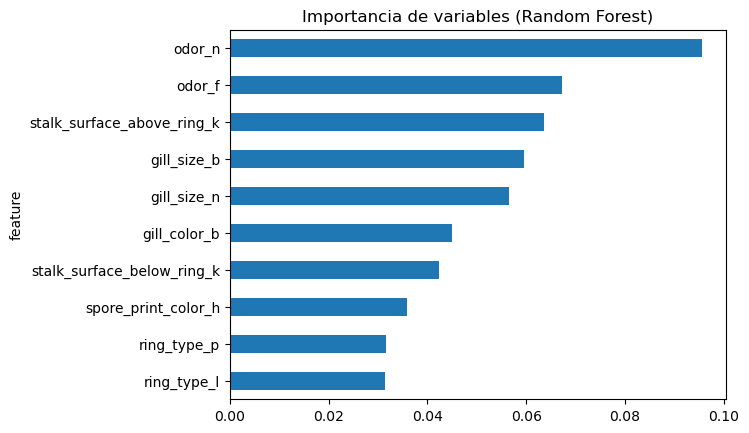

In [8]:
# Gráfica de importancia 
import matplotlib.pyplot as plt

df_importancias.head(10).plot(
    kind='barh', x='feature', y='importance', legend=False
)

plt.gca().invert_yaxis()
plt.title("Importancia de variables (Random Forest)")
plt.show()

- Se representan las variables más importantes, observándose que algunas características tienen un peso mucho mayor en la decisión del modelo que otras. Las primeras variables explican la mayor parte de la decisión del modelo.

In [9]:
# Importancia acumulada
df_importancias['importance_acum'] = df_importancias['importance'].cumsum()
print(df_importancias.head(10))

                       feature  importance  importance_acum
27                      odor_n    0.095698         0.095698
24                      odor_f    0.067237         0.162935
57  stalk_surface_above_ring_k    0.063641         0.226576
35                 gill_size_b    0.059490         0.286066
36                 gill_size_n    0.056420         0.342486
37                gill_color_b    0.045008         0.387495
61  stalk_surface_below_ring_k    0.042383         0.429878
95         spore_print_color_h    0.035756         0.465634
93                 ring_type_p    0.031576         0.497210
91                 ring_type_l    0.031397         0.528606
